# **Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes**

Los ratings y reseñas de películas son una fuente rica de datos textuales que pueden ser analizados para identificar el sentimiento subyacente, ya sea positivo o negativo. El uso de redes neuronales recurrentes (RNN) ha demostrado ser eficaz en la clasificación de secuencias de texto, ya que estas redes pueden capturar la información contextual en oraciones y palabras, identificando patrones relevantes para determinar la polaridad de una reseña.

**Redes Neuronales Recurrentes**


Las RNN son especialmente adecuadas para el análisis de datos secuenciales como texto, ya que tienen la capacidad de almacenar y recordar información previa en la secuencia, lo cual es crucial para entender el contexto. Al aplicar una RNN a reseñas de películas, la red puede ser entrenada para identificar palabras, frases y patrones que generalmente se asocian con sentimientos positivos o negativos.

**Procesamiento de Texto**

El procesamiento de texto para este proyecto implica convertir las reseñas en un formato numérico que la RNN pueda procesar. Esto se logra a través de técnicas como la tokenización y la vectorización de palabras (por ejemplo, utilizando embeddings). Luego, la RNN analizará la secuencia de palabras para clasificar cada reseña en una de dos categorías: positiva o negativa.

**Ventajas y Aplicaciones**

Implementar RNN para la clasificación de sentimientos en reseñas de películas ofrece varias ventajas:
- Detección precisa de emociones: Mejora la capacidad de capturar sentimientos más matizados en textos largos y complejos.
- Adaptabilidad a distintos idiomas y contextos: Las RNN pueden ser entrenadas en diferentes conjuntos de datos para adaptarse a lenguajes y contextos específicos, como géneros de películas o plataformas de reseñas.
- Asistencia en sistemas de recomendación: Permite mejorar las recomendaciones personalizadas en plataformas de streaming basadas en el análisis de reseñas de usuarios.

**A. Objetivo**
- Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos categorías: positiva o negativa.

**B. Conjunto de datos**
- Los datos corresponden a un dataset de reseñas de películas en IMDb, disponibles en el siguiente [enlace](https://www.kaggle.com/datasets/yasserh/imdb-movie-ratings-sentiment-analysis/data). El dataset contiene miles de reseñas etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o negativo).

**C. Actividades por realizar**
1. Preprocesamiento de las reseñas: Construir un pipeline que permita limpiar y tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas utilizando embeddings (por ejemplo, Word2Vec o GloVe).
2. Desarrollo de la arquitectura de red neuronal recurrente: Implementar una RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir capas de embedding, capas recurrentes y una capa densa de salida con activación sigmoide. Justificar la elección de cada capa del modelo.
3. Entrenamiento y evaluación del modelo: Dividir el dataset en conjuntos de entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando métricas de precisión, recall y F1-score.

## Importar librerias

In [1]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 45.7 MB/s  0:00:00


In [42]:
import pandas as pd               # Librería para manejo de dataframes
import numpy as np                # Librería para trabajar con datos matriciales
import matplotlib.pyplot as plt   # Librería de visualización
import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')  # Recomendado para soporte multilingüe/actualizado de wordnet

#Preprocesamiento de texto
nltk.download('stopwords')
from nltk import RegexpTokenizer
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer

from sklearn.decomposition import TruncatedSVD

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score   # Importar métricas de validación
from sklearn.preprocessing import StandardScaler      # Importar objeto para realizar estandarización de variables
from sklearn.metrics import accuracy_score, classification_report, f1_score, precision_score, recall_score

from time import time   # Librería para cálculos de tiempos de ejecución
import copy              # Librería para copiar los mejores pesos del modelo durante el entrenamiento




# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader   # Utilidades para construir el pipeline de datos

from gensim.models import Word2Vec


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Inicialización de semillas.

In [73]:
SEED = 0

def seed_everything(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    return seed


SEED = seed_everything(42)

## Uso de dispositivo de computo.

In [30]:
# Dispositivo de cómputo (usa GPU si está disponible de lo contrario CPU)
if torch.cuda.is_available():
    print("Nombre de la GPU:", torch.cuda.get_device_name(0))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Nombre de la GPU: Tesla T4
Usando dispositivo: cuda


## **Carga de datos**

Realizaremos la carga de datos usando la función de Pandas read_csv(), especificando la ruta y el separador del archivo.

In [31]:
data = pd.read_csv('/content/movie.csv', sep=',')
data

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1
...,...,...
39995,"""Western Union"" is something of a forgotten cl...",1
39996,This movie is an incredible piece of work. It ...,1
39997,My wife and I watched this movie because we pl...,0
39998,"When I first watched Flatliners, I was amazed....",1


**Verificación de etiquetas distintas en dataset**

In [32]:
clases_unicas = data['label'].unique()
print(f"Etiquetas únicas: {clases_unicas}")

Etiquetas únicas: [0 1]


De lo anterior se observa que hay dos clases de sentimientos en el dataset:

0: Sentimiento positivo (según fuente del dataset)

1: Sentimiento negativo (según fuente del dataset)

## Tratamiento de datos nulos y duplicados:

In [33]:
# Datos nulos
print(f'Data:\n{data.isna().sum()}')

Data:
text     0
label    0
dtype: int64


De lo anterior no hay datos nulos en el dataset.

In [34]:
# Duplicados
data.duplicated().sum()

np.int64(277)

De lo anterior se observa que hay 277 registros duplicados en el dataset de entrada.

###Eliminación de registros duplicados.

In [35]:
# Ver el número inicial de registros
print(f"Registros antes de limpiar: {len(data)}")

# Eliminar duplicados exactos
data = data.drop_duplicates().reset_index(drop=True)

# Verificar cuántos quedaron
print(f"Registros después de limpiar: {len(data)}")

Registros antes de limpiar: 40000
Registros después de limpiar: 39723


## **División de los datos**

In [36]:
X= data.drop(columns='label')
y= data['label']

In [37]:
X.shape

(39723, 1)

In [38]:
y.shape

(39723,)

### **Separación en entrenamiento, test y validación.**

In [39]:
#sSeparación 60% (train)/ 20%(test) /20% (val)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=42) # 0.25 x 0.8 = 0.2

print(X.shape[0],X_train.shape[0],X_test.shape[0],X_val.shape[0])

39723 23833 7945 7945


De lo anterior se observa que la división del conjunto de datos quedo así:

Entrenamiento: 23833 registros

Test: 7945 registros

Validación: 7945 registros


## **Pipeline de preprocesamiento de las reseñas**

Vamos a definir la función text_preprocess() para realizar todos los pasos del procesamiento de textos: limpieza, tokenización, eliminación de palabras vacías y stemming:

In [40]:
# 1. Creamos la lista de stopwords pero excluyendo las negaciones importantes
stop_words = set(stopwords.words('english'))
negations = {'not', 'no', 'never', 'neither', 'nor', 'none'}
stop_words = stop_words - negations  # Mantenemos las negaciones vivas

def text_preprocess(text):
  text = text.lower()
  tokenizer = RegexpTokenizer(r'\w+')
  lemmatizer = WordNetLemmatizer()

  tokens = tokenizer.tokenize(text)

  # Filtramos usando el conjunto modificado que preserva las negaciones
  tokens = [word for word in tokens if word not in stop_words]

  # Aplicamos lematización en lugar de stemmer
  tokens = [lemmatizer.lemmatize(word) for word in tokens]

  return ' '.join(tokens)

In [43]:
# Aplicar la función text_preprocess() a las reseñas
X_train_clean = [text_preprocess(text) for text in X_train['text']]
X_val_clean = [text_preprocess(text) for text in X_val['text']]
X_test_clean = [text_preprocess(text) for text in X_test['text']]

### **Calculo de longitud promedio de cada reseña:**

In [44]:
# Calcular la longitud de cada reseña limpia en palabras
lengths = [len(text.split()) for text in X_train_clean]

print(f"Longitud promedio: {np.mean(lengths):.1f} palabras")
print(f"Longitud máxima: {max(lengths)} palabras")
print(f"Percentil 90: {np.percentile(lengths, 90):.1f} palabras")
print(f"Percentil 95: {np.percentile(lengths, 95):.1f} palabras")
print(f"Percentil 99: {np.percentile(lengths, 99):.1f} palabras")

Longitud promedio: 126.2 palabras
Longitud máxima: 1459 palabras
Percentil 90: 250.0 palabras
Percentil 95: 327.0 palabras
Percentil 99: 493.0 palabras


**Con base a lo anterior se utilizará el valor 350 para tomar las primeras 350 palabras de cada reseña. Con lo anterior se cubre el 100% de las palabras del 95% de las reseñas. Solo se recortara menos del 5% de las reseñas largas. Este valor se utilizará más adelante como parámetro en la función "text_to_numeric_sequence" que convierte el texto limpio a secuencia numérica.**

In [45]:
# Entrenar (o cargar) los Embeddings (Word2Vec) sobre el texto limpio
sentences_train = [text.split() for text in X_train_clean]
w2v_model = Word2Vec(
    sentences=sentences_train, vector_size=100, window=5, min_count=2
)

# Construir el vocabulario basado en los embeddings para hacer la conversión numérica
vocab = {word: idx + 2 for idx, word in enumerate(w2v_model.wv.index_to_key)}
vocab['<pad>'] = 0  # Índice para el relleno de secuencias
vocab['<unk>'] = 1  # Índice para palabras desconocidas


In [46]:
# Función que convierte el texto limpio en la secuencia numérica requerida

def text_to_numeric_sequence(text, vocab, max_len=350):
  tokens = text.split()
  # Convierte cada palabra en su número/índice correspondiente del embedding
  sequence = [vocab.get(word, vocab['<unk>']) for word in tokens]

  # Asegurar longitud fija mediante Padding / Truncado
  if len(sequence) < max_len:
    sequence = sequence + [vocab['<pad>']] * (max_len - len(sequence))
  else:
    sequence = sequence[:max_len]
  return sequence

In [47]:
# Aplicar el preprocesamiento final para obtener las secuencias numéricas de entrada
X_train_seq = torch.tensor(
    [text_to_numeric_sequence(t, vocab) for t in X_train_clean],
    dtype=torch.long,
)
X_val_seq = torch.tensor(
    [text_to_numeric_sequence(t, vocab) for t in X_val_clean], dtype=torch.long
)
X_test_seq = torch.tensor(
    [text_to_numeric_sequence(t, vocab) for t in X_test_clean], dtype=torch.long
)

**Descarga de vectores Glove pre-entrenados para el embedding:**

In [5]:
!wget -q https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip

# Unzip the file
!unzip -o -q glove.6B.zip

**Función para cargar e inyectar Embeddings pre-entrenados de GloVe**

In [72]:
def load_glove_weights(glove_path, word_to_index, embedding_dim=100):
    vocab_size = len(word_to_index)
    # Inicializamos la matriz con ceros (o valores aleatorios pequeños)
    embedding_matrix = np.zeros((vocab_size, embedding_dim))

    found_words = 0
    with open(glove_path, 'r', encoding='utf-8') as f:
        for line in f:
            parts = line.strip().split(' ')
            word = parts[0]
            if word in word_to_index:
                vector = np.array(parts[1:], dtype=float)
                index = word_to_index[word]
                embedding_matrix[index] = vector
                found_words += 1

    print(f"Palabras encontradas en GloVe: {found_words} de {vocab_size}")
    return torch.tensor(embedding_matrix, dtype=torch.float32)

## **Construcción arquitectura LSTM**

In [74]:
class SentimentClassifierLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_units, output_dim=1, dropout=0.3):
        super().__init__()

        # 1. Capa de Embedding (específica para texto)
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size, embedding_dim=embedding_dim, padding_idx=0
        )

        # 2. LSTM Bidireccional
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_units,
            batch_first=True,
            bidirectional=True  # La red procesa la reseña de izquierda a derecha y de derecha a izquierda.
        )

        # 3. Capa de Dropout para regularización
        self.dropout = nn.Dropout(dropout)

        # 4. Capa Densa de salida (Multiplicada por 2 al ser bidireccional)
        self.fc = nn.Linear(hidden_units * 2, output_dim)

        # 5. Función de activación sigmoide
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # x shape: [batch_size, seq_len]

        # Pasamos por el embedding -> [batch, seq_len, embedding_dim]
        embedded = self.embedding(x)

        # Pasamos por la LSTM
        _, (h_n, _) = self.lstm(embedded)

        # Al ser bidireccional, h_n tiene 2 capas (forward y backward). Las concatenamos:
        # h_n shape: [num_layers * num_directions, batch, hidden_units]
        cat_hidden = torch.cat((h_n[-2, :, :], h_n[-1, :, :]), dim=1)

        # Aplicar el dropout al vector combinado antes de la capa lineal
        out = self.dropout(cat_hidden)

        # Capa lineal final y sigmoide para obtener la probabilidad binaria
        out = self.fc(out)
        return self.sigmoid(out).squeeze(1)

## **Instanciar el modelo.**

In [79]:

# 1. Definir los hiperparámetros
VOCAB_SIZE = len(vocab)  # Tamaño total del diccionario (incluyendo <pad> y <unk>)
EMBEDDING_DIM = 100  # Debe ser igual al vector_size de Word2Vec
HIDDEN_UNITS = 128  # Número de neuronas ocultas en la LSTM
OUTPUT_DIM = 1  # 1 sola salida (clasificación binaria: 0 o 1)
DROPOUT = 0.3

EXPERIMENT_TYPE = 'glove'  # Opciones: 'word2vec' o 'glove'

# 2. Instanciar el modelo
model = SentimentClassifierLSTM(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_units=HIDDEN_UNITS,
    output_dim=OUTPUT_DIM,
    dropout=DROPOUT,
)
if EXPERIMENT_TYPE == 'word2vec':
    print("-> Entrenando y usando Embeddings de Word2Vec localmente...")

    # Extraemos los vectores directamente del modelo Word2Vec entrenado
    embedding_matrix = np.zeros((VOCAB_SIZE, EMBEDDING_DIM))
    for word, idx in vocab.items():
        if word in w2v_model.wv:
            embedding_matrix[idx] = w2v_model.wv[word]

    model.embedding.weight.data.copy_(torch.tensor(embedding_matrix, dtype=torch.float32))

elif EXPERIMENT_TYPE == 'glove':
    print("-> Cargando e inyectando Embeddings pre-entrenados de GloVe...")

    # Invocar función para cargar y asignar pesos de GloVe usando el mismo vocabulario
    glove_weights = load_glove_weights('glove.6B.100d.txt', vocab, EMBEDDING_DIM)
    model.embedding.weight.data.copy_(glove_weights)

#Permitir ajuste fino (fine-tuning) durante el entrenamiento en ambos casos
model.embedding.weight.requires_grad = True


# 3. Mover el modelo al dispositivo disponible (GPU si la tienes, o CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

# 4. Imprimir la estructura del modelo para verificar
print(model)

-> Cargando e inyectando Embeddings pre-entrenados de GloVe...


ValueError: could not convert string to float: 'https://git-lfs.github.com/spec/v1'

In [66]:
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nNúmero total de parámetros entrenables: {n_params}")


Número total de parámetros entrenables: 4402277


**Definición de función de pérdida y optimizador:**

nn.BCELoss: Entropía cruzada binaria, ideal para problemas de clasificación binaria (equivalente a binary_crossentropy); requiere que la capa de salida ya entregue probabilidades (por ejemplo, tras una Sigmoid).

In [67]:
# Definir la función de pérdida y el optimizador
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

## **Entrenamiento del modelo:**

In [68]:
# 1. Preparar los datos de entrenamiento y validación como tensores de PyTorch
X_t_tensor = torch.tensor(X_train_seq, dtype=torch.long)
y_t_tensor = torch.tensor(y_train.values, dtype=torch.float32)

X_v_tensor = torch.tensor(X_val_seq, dtype=torch.long)
y_v_tensor = torch.tensor(y_val.values, dtype=torch.float32)

# 2. Crear los DataLoaders tanto para entrenamiento como para validación
train_dataset = TensorDataset(X_t_tensor, y_t_tensor)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

val_dataset = TensorDataset(X_v_tensor, y_v_tensor)
val_loader = DataLoader(
    val_dataset, batch_size=128, shuffle=False
)  # Lotes de 128 para validación

# 3. Configuración de Parada Temprana
n_epochs = 15
patience = 3
best_val_loss = float('inf')
epochs_no_improve = 0
best_model_state = None

history = {'loss': [], 'val_loss': []}
start = time()

print('Iniciando entrenamiento del modelo LSTM...')

# 4. Bucle principal
for epoch in range(n_epochs):
  # --- Fase de entrenamiento ---
  model.train()
  running_loss = 0.0

  for xb, yb in train_loader:
    xb, yb = xb.to(device), yb.to(device)

    optimizer.zero_grad()
    pred = model(xb)
    loss = criterion(pred, yb)

    loss.backward()
    optimizer.step()

    running_loss += loss.item() * xb.size(0)

  train_loss = running_loss / len(train_dataset)


  # --- Fase de validación (¡Ahora por lotes usando val_loader!) ---
  model.eval()
  val_running_loss = 0.0

  with torch.no_grad():
    for v_xb, v_yb in val_loader:
      v_xb, v_yb = v_xb.to(device), v_yb.to(device)

      val_pred = model(v_xb)
      loss = criterion(val_pred, v_yb)

      val_running_loss += loss.item() * v_xb.size(0)

  val_loss = val_running_loss / len(val_dataset)

  # Guardar historial
  history['loss'].append(train_loss)
  history['val_loss'].append(val_loss)

  print(
      f'Época {epoch+1}/{n_epochs} - loss: {train_loss:.4f} - val_loss:'
      f' {val_loss:.4f}'
  )

  # Lógica de Parada Temprana
  if val_loss < best_val_loss:
    best_val_loss = val_loss
    epochs_no_improve = 0
    best_model_state = copy.deepcopy(model.state_dict())
  else:
    epochs_no_improve += 1
    if epochs_no_improve >= patience:
      print(
          f'Early stopping en la época {epoch+1}: la pérdida de validación no'
          f' mejoró en {patience} épocas.'
      )
      break

# Restaurar los mejores pesos encontrados
if best_model_state is not None:
  model.load_state_dict(best_model_state)

print(f'Entrenamiento finalizado en {time() - start:.2f} segundos.')

/tmp/ipykernel_654/851176404.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_t_tensor = torch.tensor(X_train_seq, dtype=torch.long)
/tmp/ipykernel_654/851176404.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_v_tensor = torch.tensor(X_val_seq, dtype=torch.long)


Iniciando entrenamiento del modelo LSTM...
Época 1/15 - loss: 0.6351 - val_loss: 0.5811
Época 2/15 - loss: 0.5553 - val_loss: 0.5919
Época 3/15 - loss: 0.5190 - val_loss: 0.5191
Época 4/15 - loss: 0.5164 - val_loss: 0.6371
Época 5/15 - loss: 0.4605 - val_loss: 0.4511
Época 6/15 - loss: 0.4191 - val_loss: 0.4166
Época 7/15 - loss: 0.3736 - val_loss: 0.3929
Época 8/15 - loss: 0.3454 - val_loss: 0.5712
Época 9/15 - loss: 0.3692 - val_loss: 0.3467
Época 10/15 - loss: 0.2836 - val_loss: 0.3638
Época 11/15 - loss: 0.2640 - val_loss: 0.3675
Época 12/15 - loss: 0.2137 - val_loss: 0.3259
Época 13/15 - loss: 0.1861 - val_loss: 0.4527
Época 14/15 - loss: 0.1607 - val_loss: 0.3520
Época 15/15 - loss: 0.1352 - val_loss: 0.3732
Early stopping en la época 15: la pérdida de validación no mejoró en 3 épocas.
Entrenamiento finalizado en 134.96 segundos.


**Visualización de la función de pérdida a lo largo del entrenamiento:**

In [69]:
def visualization_history(resultsFit):
    """
    Esta función grafica las curvas de pérdida a lo largo de las épocas de entrenamiento
    para el conjunto de entrenamiento como el de validación.
    Parámetros:
    resultsFit = diccionario con el historial de entrenamiento en PyTorch (llaves 'loss' y 'val_loss')
    Salida:
    Gráfica de la pérdida en entrenamiento y validación.
    """
    # Llamado al entorno de la gráfica y fijar tamaño de visualización
    fig, axes = plt.subplots(1, 1, figsize=(13, 4))

    # Graficar la pérdida de la historia en entrenamiento
    axes.plot(range(len(resultsFit['loss'])), resultsFit['loss'],
           '#5a2ff4', linestyle = "-", marker = ".",
           label='Pérdida entrenamiento', lw = 2)

    # Graficar la pérdida de la historia en validación
    axes.plot(range(len(resultsFit['val_loss'])), resultsFit['val_loss'],  '#60d13e',
           label='Pérdida validación', linestyle = '-', marker = '.', lw =2)

    # Títulos de los ejes
    axes.set_xlabel('Época',fontsize=12)
    axes.set_ylabel(r'Pérdida',fontsize=12)
    axes.grid()      # Activar la cuadricula
    axes.legend(fontsize=12,loc = 'upper right')   # Establecer la legenda


    plt.tight_layout() # Ajusta automáticamente el diseño de la figura
    plt.show()


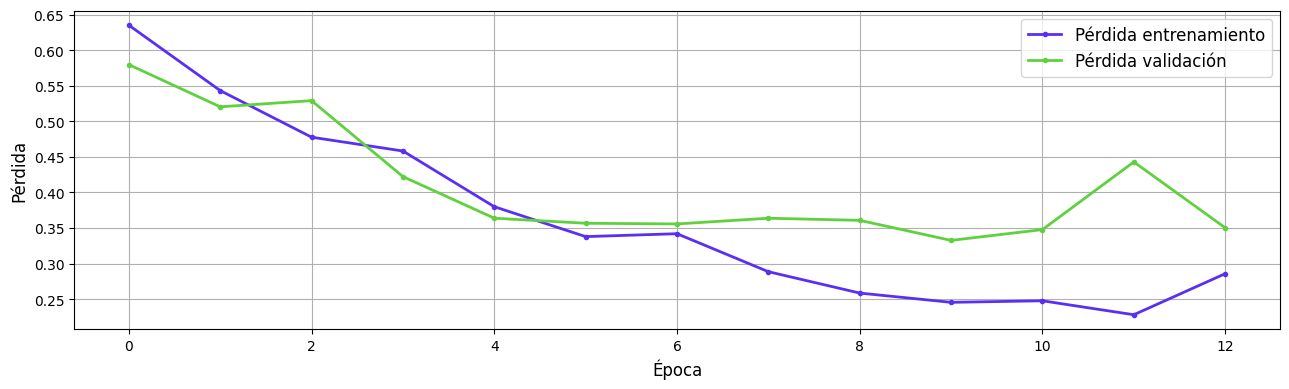

In [26]:
visualization_history(history)

## **Evaluación del modelo:**

In [70]:
# 1. Preparar los datos de prueba como tensores y DataLoader
X_test_tensor = torch.tensor(X_test_seq, dtype=torch.long)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(
    test_dataset, batch_size=128, shuffle=False
)  # Lotes de 128

# 2. Poner el modelo en modo evaluación
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
  for x_b, y_b in test_loader:
    x_b = x_b.to(device)

    # Obtener probabilidades del batch
    preds = model(x_b)

    # Guardar predicciones y etiquetas reales pasándolas a la CPU
    all_preds.append(preds.cpu())
    all_targets.append(y_b)

# 3. Concatenar todos los lotes en dos grandes tensores
test_preds = torch.cat(all_preds)
y_test_tensor = torch.cat(all_targets)

# 4. Convertir probabilidades a clases binarias (>= 0.5 es 1 / Positivo)
y_pred_binary = (test_preds >= 0.5).int().numpy()
y_true = y_test_tensor.int().numpy()

# 5. Calcular las métricas solicitadas
accuracy = accuracy_score(y_true, y_pred_binary)
precision = precision_score(y_true, y_pred_binary, average='binary')
recall = recall_score(y_true, y_pred_binary, average='binary')
f1 = f1_score(y_true, y_pred_binary, average='binary')

# 6. Imprimir los resultados
print('=' * 40)
print(' RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA')
print('=' * 40)
print(f'Exactitud (Accuracy): {accuracy * 100:.2f}%')
print(f'Precisión (Precision): {precision:.4f}')
print(f'Exhaustividad (Recall): {recall:.4f}')
print(f'Puntuación F1 (F1-score): {f1:.4f}')
print('=' * 40)

# Reporte detallado por clase de Scikit-Learn
print('\nReporte detallado de clasificación:')
print(
    classification_report(
        y_true, y_pred_binary, target_names=['Negativa (0)', 'Positiva (1)']
    )
)

/tmp/ipykernel_654/2563779785.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_test_tensor = torch.tensor(X_test_seq, dtype=torch.long)


 RESULTADOS FINALES EN EL CONJUNTO DE PRUEBA
Exactitud (Accuracy): 86.18%
Precisión (Precision): 0.8599
Exhaustividad (Recall): 0.8629
Puntuación F1 (F1-score): 0.8614

Reporte detallado de clasificación:
              precision    recall  f1-score   support

Negativa (0)       0.86      0.86      0.86      3991
Positiva (1)       0.86      0.86      0.86      3954

    accuracy                           0.86      7945
   macro avg       0.86      0.86      0.86      7945
weighted avg       0.86      0.86      0.86      7945

